# Mini Project: Prediksi Besar Diskon Game di Steam Kelompok 2:
1. Lutfi Raditya Warsono
2. Farid Khaliq Ahmad
3. Azfa Hilmy Abiyan


# 1. Persiapan

In [ ]:
import os
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_validate, GridSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


path = kagglehub.dataset_download("evyatarbensegal/steam-full-market-dataset", path="game_analytics.csv")
df = pd.read_csv(path)
print(df.shape)

Using Colab cache for faster access to the 'steam-full-market-dataset' dataset.
(220702, 28)


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 220702 entries, 0 to 220701
Data columns (total 28 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   appid               220702 non-null  int64  
 1   name                212864 non-null  object 
 2   genre_primary       219160 non-null  object 
 3   developer           159302 non-null  object 
 4   publisher           147347 non-null  object 
 5   publisher_tier      220702 non-null  object 
 6   price_initial       169647 non-null  float64
 7   price_final         148137 non-null  float64
 8   discount_percent    148137 non-null  float64
 9   owners_min          220699 non-null  float64
 10  owners_max          220699 non-null  float64
 11  owners_midpoint     220699 non-null  float64
 12  positive_reviews    220699 non-null  float64
 13  negative_reviews    220699 non-null  float64
 14  tags                92142 non-null   object 
 15  release_date        173584 non-nul

In [ ]:
print(df["discount_percent"].isna().sum())
print((df["discount_percent"] == 0).sum())
print((df["discount_percent"] > 0).sum())

72565
135161
12976


In [ ]:
sale = df[df["discount_percent"] > 0].copy()
print(sale.shape)

(12976, 28)


## 2. EDA

2a: komposisi target di seluruh data

In [ ]:
jumlah = {
    "Kosong": df["discount_percent"].isna().sum(),
    "Nol (tidak diskon)": (df["discount_percent"] == 0).sum(),
    "Diskon > 0": (df["discount_percent"] > 0).sum(),
}
for nama, n in jumlah.items():
    print(f"{nama:<20}{n:>8}  {n / len(df) * 100:.1f}%")

Kosong                 72565  32.9%
Nol (tidak diskon)    135161  61.2%
Diskon > 0             12976  5.9%


Tiga hitungan tadi dirapikan jadi tabel dengan persentase terhadap seluruh baris (len(df)). Ini bahan temuan pertama: hanya 5,9% game yang sedang diskon, sehingga data disaring.

2b: ringkasan data game berdiskon

In [ ]:
sale.info()


<class 'pandas.core.frame.DataFrame'>
Index: 12976 entries, 2 to 220651
Data columns (total 28 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   appid               12976 non-null  int64  
 1   name                12850 non-null  object 
 2   genre_primary       12946 non-null  object 
 3   developer           11632 non-null  object 
 4   publisher           11151 non-null  object 
 5   publisher_tier      12976 non-null  object 
 6   price_initial       12976 non-null  float64
 7   price_final         12976 non-null  float64
 8   discount_percent    12976 non-null  float64
 9   owners_min          12976 non-null  float64
 10  owners_max          12976 non-null  float64
 11  owners_midpoint     12976 non-null  float64
 12  positive_reviews    12976 non-null  float64
 13  negative_reviews    12976 non-null  float64
 14  tags                7515 non-null   object 
 15  release_date        12966 non-null  object 
 16  ccu     

In [ ]:
sale["discount_percent"].describe().round(2)

,discount_percent
count,12976.00
mean,55.45
std,23.45
min,10.00
25%,40.00
50%,51.00
75%,75.00
max,100.00


In [ ]:
sale["discount_percent"].value_counts().head(10)

,count
discount_percent,
50.0,1757
80.0,1148
51.0,1070
20.0,870
40.0,802
60.0,735
75.0,729
90.0,707
70.0,627


info() menampilkan tipe dan jumlah data terisi per kolom, describe() meringkas sebaran target, dan value_counts() menampilkan 10 nilai diskon yang paling sering muncul. Dari hasil sebelumnya, describe seharusnya mean 55,45, median 51, minimum 10, dan maksimum 100.

2c: visualisasi 1, sebaran target (histogram)

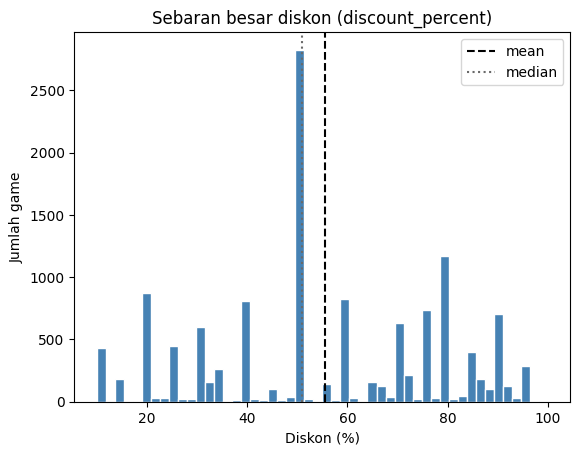

In [ ]:
plt.hist(sale["discount_percent"], bins=50, color="steelblue", edgecolor="white")
plt.axvline(sale["discount_percent"].mean(), color="black", linestyle="--", label="mean")
plt.axvline(sale["discount_percent"].median(), color="dimgray", linestyle=":", label="median")
plt.title("Sebaran besar diskon (discount_percent)")
plt.xlabel("Diskon (%)")
plt.ylabel("Jumlah game")
plt.legend()
plt.show()

2d: visualisasi 2, harga awal vs diskon (scatter)

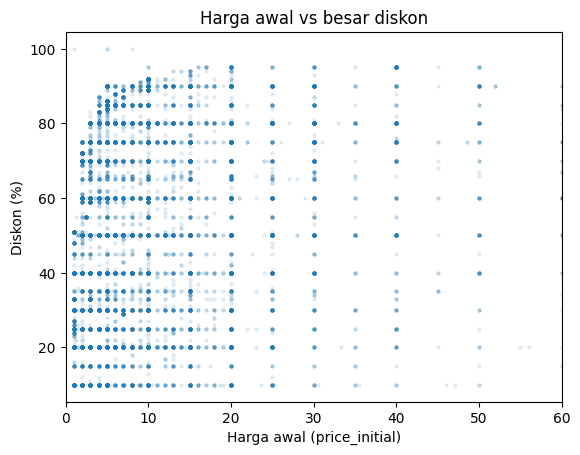

In [ ]:
plt.scatter(sale["price_initial"], sale["discount_percent"], alpha=0.1, s=5)
plt.xlim(0, 60)
plt.title("Harga awal vs besar diskon")
plt.xlabel("Harga awal (price_initial)")
plt.ylabel("Diskon (%)")
plt.show()

Tumpukan titik di harga rendah, dan titik-titik jauh di kanan. Titik padat di sekitar harga 199,99 dengan diskon 95% adalah kelompok 202 baris yang kita bahas tadi.

2e: visualisasi 3, diskon per genre (boxplot)

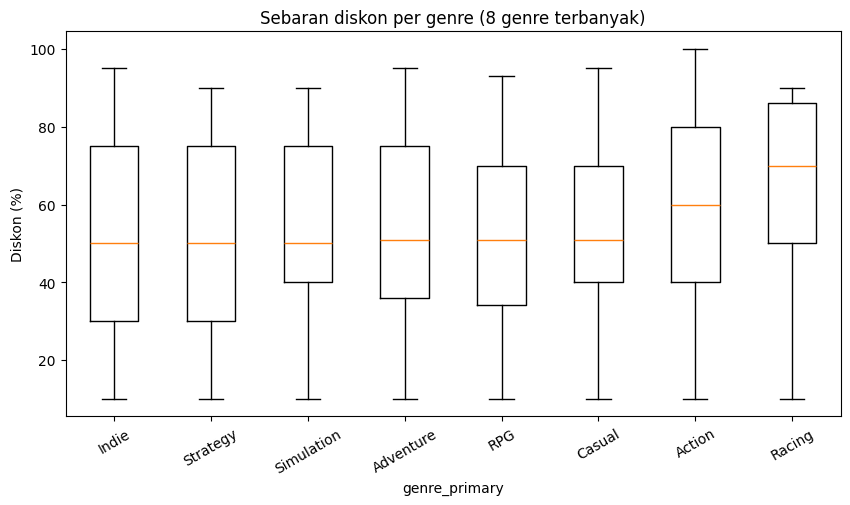

,discount_percent
genre_primary,
Indie,50.0
Strategy,50.0
Simulation,50.0
Adventure,51.0
RPG,51.0
Casual,51.0
Action,60.0
Racing,70.0


In [ ]:
top_genre = sale["genre_primary"].value_counts().head(8).index   # 8 genre terbanyak
median_per_genre = (sale[sale["genre_primary"].isin(top_genre)]
                    .groupby("genre_primary")["discount_percent"].median().sort_values())
urutan = median_per_genre.index
diskon_per_genre = [sale.loc[sale["genre_primary"] == g, "discount_percent"] for g in urutan]

plt.figure(figsize=(10, 5))
plt.boxplot(diskon_per_genre)
plt.xticks(range(1, len(urutan) + 1), urutan, rotation=30)
plt.title("Sebaran diskon per genre (8 genre terbanyak)")
plt.xlabel("genre_primary")
plt.ylabel("Diskon (%)")
plt.show()

median_per_genre

Hanya 8 genre terbanyak yang dipakai (masing-masing 171 baris atau lebih)

2f: visualisasi 4, korelasi antar kolom (heatmap)

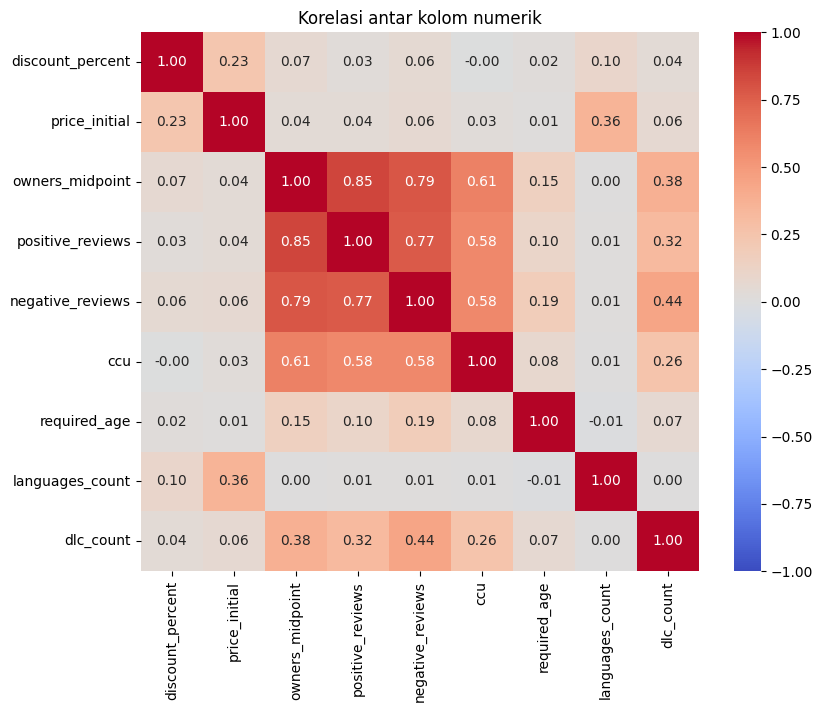

,discount_percent
discount_percent,1.00
price_initial,0.23
languages_count,0.10
owners_midpoint,0.07
negative_reviews,0.06
dlc_count,0.04
positive_reviews,0.03
required_age,0.02
ccu,-0.00


In [ ]:
kolom_num = ["discount_percent", "price_initial", "owners_midpoint", "positive_reviews",
             "negative_reviews", "ccu", "required_age", "languages_count", "dlc_count"]
korelasi = sale[kolom_num].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(korelasi, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0)
plt.title("Korelasi antar kolom numerik")
plt.show()

korelasi["discount_percent"].sort_values(ascending=False).round(2)

kolom dipilih manual karena appid hanya ID, steam_deck konstan (semua False, korelasinya tidak bisa dihitung), peak_ccu kembar ccu, dan owners_min dan owners_max sudah diwakili owners_midpoint. Dari hasil sebelumnya, price_initial seharusnya paling kuat (sekitar 0,23), sedangkan yang lain di bawah 0,1.

2g: tambahan, diskon per rentang harga dan komposisi tier

In [ ]:
bin_harga = pd.cut(sale["price_initial"], [0, 1, 5, 10, 20, 1000])
sale.groupby(bin_harga, observed=True)["discount_percent"].agg(["count", "median", "mean"]).round(1)

,count,median,mean
price_initial,,,
"(0, 1]",1619,51.0,43.4
"(1, 5]",4500,50.0,54.5
"(5, 10]",3036,60.0,57.0
"(10, 20]",2526,60.0,57.6
"(20, 1000]",1295,70.0,65.7


In [ ]:
(sale["publisher_tier"].value_counts(normalize=True) * 100).round(2)

,proportion
publisher_tier,
Indie,95.90
AAA,2.07
AA,2.03


pd.cut memotong harga menjadi lima kelompok, lalu median dan mean diskon dihitung per kelompok. Baris kedua memakai normalize=True seperti di Hari 1 untuk melihat proporsi tiap tier.

# 3. Data Cleaning

3a: salinan untuk dibersihkan

In [ ]:
df_clean = sale.copy()   # `sale` tetap utuh
print("Ukuran awal:", df_clean.shape)

Ukuran awal: (12976, 28)


3b: baris anomali (rumus harga tidak cocok)

In [ ]:
# harga akhir seharusnya = harga awal x (1 - diskon/100)
hitung = (df_clean["price_initial"] * (1 - df_clean["discount_percent"] / 100)).round(2)
selisih = (hitung - df_clean["price_final"]).abs()
anomali = df_clean[selisih > 0.05]
print("Jumlah baris tidak konsisten:", len(anomali))
anomali[["name", "price_initial", "price_final", "discount_percent"]]

Jumlah baris tidak konsisten: 4


,name,price_initial,price_final,discount_percent
17477,Crown Champion: Legends of the Arena,4.99,0.69,100.0
110882,Kiki,4.99,4.99,100.0
177347,Cursedland,0.99,0.99,100.0
216127,Voidtrain - Tour de Void,7.99,7.99,100.0


In [ ]:
df_clean = df_clean.drop(index=anomali.index)
print("Ukuran setelah dibuang:", df_clean.shape)

Ukuran setelah dibuang: (12972, 28)


3c: duplikat

In [ ]:
print("Duplikat:", df_clean.duplicated().sum())
df_clean = df_clean.drop_duplicates()
print("Ukuran setelah duplikat dibuang:", df_clean.shape)

Duplikat: 0
Ukuran setelah duplikat dibuang: (12972, 28)


3d: kolom yang kosongnya lebih dari sepertiga

In [ ]:
persen_missing = (df_clean.isnull().mean() * 100).sort_values(ascending=False)
persen_missing.head(10).round(1)

,0
controller_support,69.6
achievement_count,49.5
tags,42.1
pc_req_rec,36.2
publisher,14.1
developer,10.4
pc_req_min,4.3
name,1.0
genre_primary,0.2
release_date,0.1


In [ ]:
kolom_buang = persen_missing[persen_missing > 100 / 3].index   # kosong lebih dari 33,3%
df_clean = df_clean.drop(columns=kolom_buang)
print("Kolom yang dibuang:", list(kolom_buang))

Kolom yang dibuang: ['controller_support', 'achievement_count', 'tags', 'pc_req_rec']


3e: kolom yang tidak dipakai sebagai fitur

In [ ]:
kolom_tidak_dipakai = ["appid", "name", "developer", "publisher", "pc_req_min",
                       "price_final", "peak_ccu", "owners_min", "owners_max", "steam_deck", "is_free"]
df_clean = df_clean.drop(columns=kolom_tidak_dipakai)

3f: tanggal rilis dan sisa nilai kosong

In [ ]:
df_clean["tahun_rilis"] = pd.to_datetime(df_clean["release_date"], errors="coerce").dt.year
df_clean = df_clean.drop(columns="release_date")

df_clean["genre_primary"] = df_clean["genre_primary"].fillna(df_clean["genre_primary"].mode()[0])   # kategorik: modus
df_clean["tahun_rilis"] = df_clean["tahun_rilis"].fillna(df_clean["tahun_rilis"].median())          # numerik: median
df_clean["tahun_rilis"] = df_clean["tahun_rilis"].astype(int)
print("Sisa nilai kosong:", df_clean.isnull().sum().sum())

Sisa nilai kosong: 0


In [ ]:
df_clean.loc[df_clean["languages_count"] == 0, "languages_count"] = np.nan   # 0 jadi kosong
df_clean["languages_count"] = df_clean["languages_count"].fillna(df_clean["languages_count"].median())
print((df_clean["languages_count"] == 0).sum(), df_clean["languages_count"].isnull().sum())

0 0


3g: missing tersamar (angka 0 yang sebenarnya kosong)

In [ ]:
for kolom in ["languages_count", "owners_midpoint", "price_initial"]:
    print(kolom, (df_clean[kolom] == 0).sum())

languages_count 0
owners_midpoint 0
price_initial 0


3h: outlier harga (metode IQR)

In [ ]:
Q1 = df_clean["price_initial"].quantile(0.25)
Q3 = df_clean["price_initial"].quantile(0.75)
IQR = Q3 - Q1
batas_atas = Q3 + 1.5 * IQR
print("Batas atas:", round(batas_atas, 2))
print("Jumlah di atas batas:", (df_clean["price_initial"] > batas_atas).sum())
df_clean.nlargest(5, "price_initial")[["price_initial", "discount_percent"]]

Batas atas: 28.0
Jumlah di atas batas: 934


,price_initial,discount_percent
130388,999.98,50.0
61328,199.99,95.0
63391,199.99,95.0
63394,199.99,95.0
63721,199.99,95.0


3i: encoding

In [ ]:
jumlah_genre = df_clean["genre_primary"].value_counts()
genre_jarang = jumlah_genre[jumlah_genre < 100].index
df_clean["genre_primary"] = df_clean["genre_primary"].replace(list(genre_jarang), "Other")   # genre kecil digabung

df_clean["is_early_access"] = df_clean["is_early_access"].astype(int)   # True/False jadi 1/0
df_clean = pd.get_dummies(df_clean, columns=["genre_primary", "publisher_tier"], drop_first=True, dtype=int)

In [ ]:
dup = df_clean[df_clean.duplicated(keep=False)]   # semua baris yang punya kembaran
print("Baris yang punya kembaran:", len(dup))
print(dup["discount_percent"].value_counts().head(5))
print(dup["price_initial"].value_counts().head(5))

Baris yang punya kembaran: 2581
discount_percent
50.0    389
51.0    364
20.0    268
40.0    263
10.0    169
Name: count, dtype: int64
price_initial
0.99    655
1.99    376
4.99    330
2.99    280
3.99    157
Name: count, dtype: int64


In [ ]:
sebelum = df_clean["discount_percent"].describe().round(2)
sesudah = df_clean.drop_duplicates()["discount_percent"].describe().round(2)
pd.DataFrame({"sebelum": sebelum, "sesudah": sesudah})

,sebelum,sesudah
count,12972.00,11089.00
mean,55.43,56.39
std,23.44,23.35
min,10.00,10.00
25%,40.00,40.00
50%,51.00,51.00
75%,75.00,79.00
max,95.00,95.00


In [ ]:
df_clean = df_clean.drop_duplicates()
print("Ukuran setelah duplikat dibuang:", df_clean.shape)

Ukuran setelah duplikat dibuang: (11089, 21)


3j: cek akhir

In [ ]:
print("Nilai kosong:", df_clean.isnull().sum().sum())
print("Duplikat:", df_clean.duplicated().sum())
print("Kolom bukan angka:", df_clean.select_dtypes(exclude="number").columns.tolist())
print("Ukuran akhir:", df_clean.shape)

Nilai kosong: 0
Duplikat: 0
Kolom bukan angka: []
Ukuran akhir: (11089, 21)


### 4. Split Data

Pada tahap ini, kita memisahkan kolom target (`discount_percent`) dari fitur-fitur lainnya, kemudian membagi dataset menjadi data latih (*training set*) dan data uji (*testing set*).

In [ ]:
# Memastikan seluruh proses cleaning sebelumnya dieksekusi untuk membuat df_clean
try:
    df_clean
except NameError:
    print("Membangun ulang df_clean dari dataset asli...")
    # 1. Ambil game yang sedang diskon
    df_clean = df[df["discount_percent"] > 0].copy()

    # 2. Buang baris anomali harga
    hitung = (df_clean["price_initial"] * (1 - df_clean["discount_percent"] / 100)).round(2)
    selisih = (hitung - df_clean["price_final"]).abs()
    anomali = df_clean[selisih > 0.05]
    df_clean = df_clean.drop(index=anomali.index)

    # 3. Buang kolom yang memiliki missing value > 33%
    persen_missing = (df_clean.isnull().mean() * 100)
    kolom_buang = persen_missing[persen_missing > 100/3].index
    df_clean = df_clean.drop(columns=kolom_buang)

    # 4. Buang kolom non-fitur
    kolom_tidak_dipakai = ["appid", "name", "developer", "publisher", "pc_req_min",
                           "price_final", "peak_ccu", "owners_min", "owners_max", "steam_deck", "is_free"]
    df_clean = df_clean.drop(columns=kolom_tidak_dipakai, errors='ignore')

    # 5. Handling missing values & datetime
    df_clean["tahun_rilis"] = pd.to_datetime(df_clean["release_date"], errors="coerce").dt.year
    df_clean = df_clean.drop(columns="release_date", errors='ignore')
    df_clean["genre_primary"] = df_clean["genre_primary"].fillna(df_clean["genre_primary"].mode()[0])
    df_clean["tahun_rilis"] = df_clean["tahun_rilis"].fillna(df_clean["tahun_rilis"].median()).astype(int)

    # Handling 0 values on language
    df_clean.loc[df_clean["languages_count"] == 0, "languages_count"] = np.nan
    df_clean["languages_count"] = df_clean["languages_count"].fillna(df_clean["languages_count"].median())

    # 6. Encoding & merging rare genres
    jumlah_genre = df_clean["genre_primary"].value_counts()
    genre_jarang = jumlah_genre[jumlah_genre < 100].index
    df_clean["genre_primary"] = df_clean["genre_primary"].replace(list(genre_jarang), "Other")
    df_clean["is_early_access"] = df_clean["is_early_access"].astype(int)
    df_clean = pd.get_dummies(df_clean, columns=["genre_primary", "publisher_tier"], drop_first=True, dtype=int)

    # 7. Drop duplicates
    df_clean = df_clean.drop_duplicates()

# 1. Pisahkan fitur (X) dan target (y)
X = df_clean.drop(columns=["discount_percent"])
y = df_clean["discount_percent"]

# 2. Bagi menjadi data latih (80%) dan data uji (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Tampilkan ukuran hasil pembagian
print("Ukuran X_train:", X_train.shape)
print("Ukuran X_test:", X_test.shape)
print("Ukuran y_train:", y_train.shape)
print("Ukuran y_test:", y_test.shape)

Ukuran X_train: (8871, 20)
Ukuran X_test: (2218, 20)
Ukuran y_train: (8871,)
Ukuran y_test: (2218,)


### 5. Model Standar (Baseline Model)

Pada bagian ini, kita menggunakan model **Linear Regression** sebagai model standar awal untuk memprediksi `discount_percent` berdasarkan fitur-fitur yang sudah kita bersihkan.

In [ ]:
# 1. Membuat dan melatih model standar
model_baseline = LinearRegression()
model_baseline.fit(X_train, y_train)

# 2. Prediksi pada data latih
y_pred_train = model_baseline.predict(X_train)

# 3. Menghitung metrik data latih
mae_train = mean_absolute_error(y_train, y_pred_train)
rmse_train = np.sqrt(mean_squared_error(y_train, y_pred_train))
r2_train = r2_score(y_train, y_pred_train)

# 4. Menampilkan hasil evaluasi data latih
hasil_train = pd.DataFrame({
    "Metrik": ["MAE", "RMSE", "R²"],
    "Data Latih": [mae_train, rmse_train, r2_train]
})

display(hasil_train.round(4))

,Metrik,Data Latih
0,MAE,16.4457
1,RMSE,19.9904
2,R²,0.2696


In [ ]:
# 1. Inisialisasi dan Latih Model Standar
model_baseline = LinearRegression()
model_baseline.fit(X_train, y_train)

# 2. Lakukan Prediksi pada Data Uji
y_pred = model_baseline.predict(X_test)

# 3. Buat DataFrame Perbandingan untuk melihat "miss" secara langsung
# Menggunakan np.abs() karena operasi NumPy array tidak memiliki metode .abs() langsung
df_eval = pd.DataFrame({
    'Diskon Sebenarnya (%)': y_test.values,
    'Prediksi Model (%)': y_pred.round(2),
    'Selisih (Miss) %': np.abs(y_test.values - y_pred).round(2)
})

print("=== Contoh Hasil Prediksi vs Aktual (10 Baris Pertama) ===")
display(df_eval.head(10))

=== Contoh Hasil Prediksi vs Aktual (10 Baris Pertama) ===


,Diskon Sebenarnya (%),Prediksi Model (%),Selisih (Miss) %
0,85.0,64.64,20.36
1,25.0,50.06,25.06
2,90.0,65.78,24.22
3,35.0,73.00,38.00
4,35.0,53.40,18.40
5,75.0,74.53,0.47
6,80.0,82.33,2.33
7,80.0,63.70,16.30
8,90.0,69.03,20.97
9,80.0,60.07,19.93


In [ ]:
# 4. Evaluasi Metrik Model Standar
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("=== Metrik Evaluasi Model Standar ===")
print(f"Mean Absolute Error (MAE) : {mae:.2f}%")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}%")
print(f"R-squared (R2 Score)       : {r2:.4f}")

=== Metrik Evaluasi Model Standar ===
Mean Absolute Error (MAE) : 16.33%
Root Mean Squared Error (RMSE): 19.73%
R-squared (R2 Score)       : 0.2760


# 6. Model Lain (Decicion Tree dan Random Forest)

6a. model lain dengan cross-validation

In [ ]:
model_regresi = {                                                       # aturan sama untuk semua model
    "Linear Regression": LinearRegression(),                            # model standar
    "Decision Tree": DecisionTreeRegressor(random_state=42),            # satu pohon, tanpa batas kedalaman
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),   # 100 pohon, dirata-rata
    "Decision Tree (max_depth=7)": DecisionTreeRegressor(max_depth=7, random_state=42),   # hasil tuning
}

hasil_cv = []                                                           # tempat menyimpan hasil tiap model
for nama, model in model_regresi.items():                               # nilai tiap model dengan aturan sama
    # 5 lipatan yang sama untuk semua model, hanya di data latih
    cv = cross_validate(model, X_train, y_train, cv=5,
                        scoring=["neg_mean_absolute_error", "neg_root_mean_squared_error", "r2"],
                        return_train_score=True)
    hasil_cv.append({"model": nama,                                     # satu baris tabel
                     "MAE CV": -cv["test_neg_mean_absolute_error"].mean(),
                     "RMSE CV": -cv["test_neg_root_mean_squared_error"].mean(),
                     "R² CV": cv["test_r2"].mean(),
                     "std R² CV": cv["test_r2"].std(),
                     "R² latih": cv["train_r2"].mean(),
                     "selisih R²": cv["train_r2"].mean() - cv["test_r2"].mean(),
                     "waktu latih (detik)": cv["fit_time"].sum()})

tabel_cv = pd.DataFrame(hasil_cv).sort_values("R² CV", ascending=False)   # urut dari R² CV tertinggi
format_cv = {"MAE CV": "{:.2f}", "RMSE CV": "{:.2f}", "R² CV": "{:.3f}", "std R² CV": "{:.3f}",
             "R² latih": "{:.3f}", "selisih R²": "{:.3f}", "waktu latih (detik)": "{:.2f}"}
tabel_cv.style.format(format_cv).hide(axis="index")

model,MAE CV,RMSE CV,R² CV,std R² CV,R² latih,selisih R²,waktu latih (detik)
Random Forest,12.49,16.43,0.506,0.019,0.907,0.400,15.09
Decision Tree (max_depth=7),13.64,17.35,0.449,0.017,0.502,0.053,0.10
Linear Regression,16.51,20.14,0.258,0.022,0.271,0.013,0.28
Decision Tree,15.48,21.85,0.127,0.025,0.968,0.841,0.46


6b: tuning dengan GridSearchCV

Tuning Decicion Tree

In [ ]:
param_pohon = {"max_depth": [2, 3, 5, 7, 10, 15, 20, None]}            # None = tanpa batas (pohon tadi)
grid_pohon = GridSearchCV(DecisionTreeRegressor(random_state=42), param_pohon,
                          cv=5, scoring="neg_mean_absolute_error", return_train_score=True)
grid_pohon.fit(X_train, y_train)                                        # 8 nilai x 5 lipatan = 40 kali latihan

tabel_pohon = pd.DataFrame({"max_depth": [str(p["max_depth"]) for p in grid_pohon.cv_results_["params"]],
                            "MAE CV": -grid_pohon.cv_results_["mean_test_score"],
                            "MAE latih": -grid_pohon.cv_results_["mean_train_score"]})
print("best_params_:", grid_pohon.best_params_)
print(f"MAE CV terbaik: {-grid_pohon.best_score_:.2f}")
tabel_pohon.style.format({"MAE CV": "{:.2f}", "MAE latih": "{:.2f}"}).hide(axis="index")

best_params_: {'max_depth': 7}
MAE CV terbaik: 13.64


max_depth,MAE CV,MAE latih
2,15.79,15.78
3,14.98,14.95
5,14.20,13.91
7,13.64,12.93
10,13.70,11.21
15,14.36,6.70
20,15.05,2.90
None,15.48,0.99


Tuning Random Forest

In [ ]:
param_hutan = {"max_depth": [5, 10, 15, None], "min_samples_leaf": [1, 5, 10]}   # 12 kombinasi
grid_hutan = GridSearchCV(RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
                          param_hutan, cv=5, scoring="neg_mean_absolute_error", return_train_score=True)
grid_hutan.fit(X_train, y_train)                                        # 12 kombinasi x 5 lipatan = 60 kali latihan

hasil_hutan = grid_hutan.cv_results_["params"]
tabel_hutan = pd.DataFrame({"max_depth": [str(p["max_depth"]) for p in hasil_hutan],
                            "min_samples_leaf": [p["min_samples_leaf"] for p in hasil_hutan],
                            "MAE CV": -grid_hutan.cv_results_["mean_test_score"],
                            "MAE latih": -grid_hutan.cv_results_["mean_train_score"]}).sort_values("MAE CV")
print("best_params_:", grid_hutan.best_params_)
print(f"MAE CV terbaik: {-grid_hutan.best_score_:.2f}")
tabel_hutan.style.format({"MAE CV": "{:.2f}", "MAE latih": "{:.2f}"}).hide(axis="index")

best_params_: {'max_depth': None, 'min_samples_leaf': 1}
MAE CV terbaik: 12.49


max_depth,min_samples_leaf,MAE CV,MAE latih
None,1,12.49,5.13
15,1,12.53,7.84
None,5,12.61,9.60
15,5,12.67,10.06
None,10,12.86,11.15
15,10,12.88,11.26
10,1,12.97,11.18
10,5,13.03,11.67
10,10,13.13,12.07
5,1,14.03,13.80


6c: tabel akhir dan data uji dibuka satu kali

In [ ]:
model_final = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)   # model terpilih
model_final.fit(X_train, y_train)                     # latih di seluruh data latih

pred_train = model_final.predict(X_train)             # tebak data yang sudah dilihat
pred_test = model_final.predict(X_test)               # tebak data uji (dibuka SATU kali)

hasil_final = pd.DataFrame({
    "metrik": ["MAE", "RMSE", "R²"],
    "data latih": [mean_absolute_error(y_train, pred_train),
                   np.sqrt(mean_squared_error(y_train, pred_train)),
                   r2_score(y_train, pred_train)],
    "data uji": [mean_absolute_error(y_test, pred_test),
                 np.sqrt(mean_squared_error(y_test, pred_test)),
                 r2_score(y_test, pred_test)]})
hasil_final["selisih (latih - uji)"] = hasil_final["data latih"] - hasil_final["data uji"]
hasil_final.style.format({"data latih": "{:.3f}", "data uji": "{:.3f}", "selisih (latih - uji)": "{:.3f}"}).hide(axis="index")

metrik,data latih,data uji,selisih (latih - uji)
MAE,5.133,12.413,-7.280
RMSE,7.209,16.282,-9.073
R²,0.905,0.507,0.398


### 7. Visualisasi Evaluasi Model Standar

Untuk melengkapi tahap evaluasi, kita memvisualisasikan perbandingan antara nilai diskon aktual (sebenarnya) dengan hasil prediksi model standar, serta melihat distribusi error (*residual*).

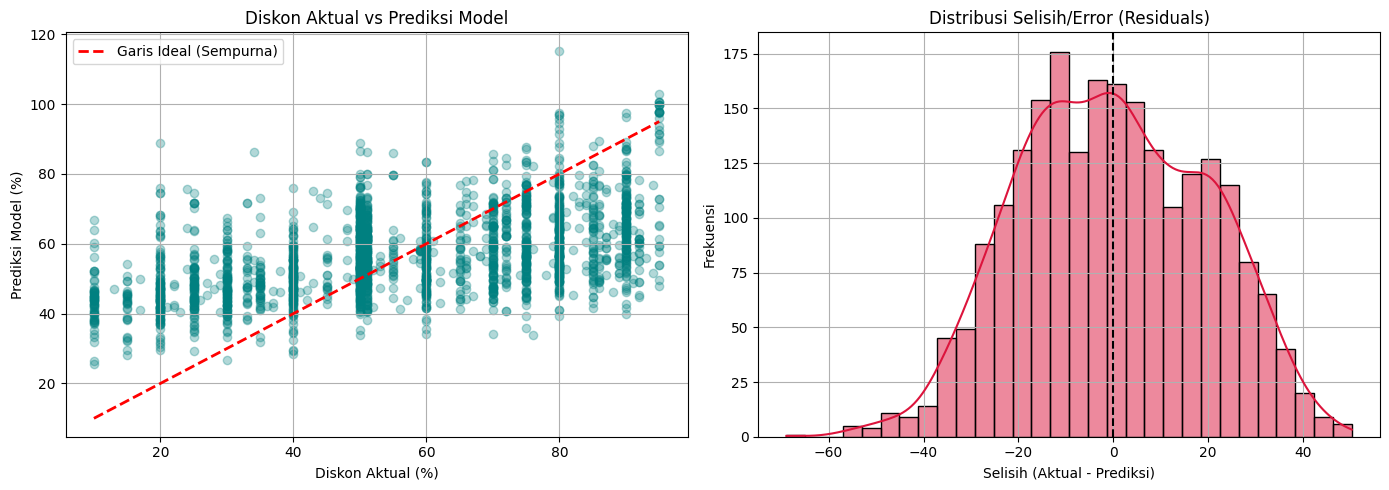

In [ ]:
# Hitung error/residual
error = y_test - y_pred

plt.figure(figsize=(14, 5))

# 1. Scatter Plot Aktual vs Prediksi
plt.subplot(1, 2, 1)
plt.scatter(y_test, y_pred, alpha=0.3, color='teal')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Garis Ideal (Sempurna)')
plt.title('Diskon Aktual vs Prediksi Model')
plt.xlabel('Diskon Aktual (%)')
plt.ylabel('Prediksi Model (%)')
plt.legend()
plt.grid(True)

# 2. Histogram Distribusi Error
plt.subplot(1, 2, 2)
sns.histplot(error, kde=True, color='crimson', bins=30)
plt.axvline(0, color='black', linestyle='--')
plt.title('Distribusi Selisih/Error (Residuals)')
plt.xlabel('Selisih (Aktual - Prediksi)')
plt.ylabel('Frekuensi')
plt.grid(True)

plt.tight_layout()
plt.show()

### 8. Pemilihan Model Akhir (Model Selection)

Berdasarkan hasil pengujian *Cross-Validation* dan evaluasi pada *Test Set*, model **Random Forest Regressor** dipilih sebagai model akhir karena:
1. Memiliki performa terbaik dengan nilai MAE terkecil (~12.41% pada data uji).
2. Mampu menjelaskan sekitar 50.7% variansi dari besar diskon ($R^2 \approx 0.507$), jauh lebih tinggi dibandingkan model standar Linear Regression ($R^2 \approx 0.276$).

### Perbandingan Performa Model (Data Uji)

Berikut adalah tabel perbandingan performa langsung antara **Model Standar (Linear Regression)** dan **Model Terbaik Terpilih (Random Forest)** pada data uji (*Test Set*):

| Metrik Evaluasi | Model Standar (Linear Regression) | Model Akhir Terpilih (Random Forest) | Peningkatan Performa | Interpretasi Sederhana (Bahasa Awam) |
| :--- | :---: | :---: | :---: | :--- |
| **MAE** (Rata-rata kesalahan mutlak) | 16.33% | **12.41%** | **~24% Lebih Akurat** | Selisih tebakan diskon model akhir rata-rata hanya meleset sebesar 12.41% dari diskon asli. |
| **RMSE** (Hukuman kesalahan besar) | 19.73% | **16.28%** | **~17.5% Lebih Stabil** | Model akhir lebih tangguh dan jarang membuat kesalahan tebakan yang sangat fatal. |
| **R² Score** (Akurasi variansi) | 0.2760 | **0.5069** | **+83.6% Penjelasan Data** | Model akhir mampu menjelaskan 50.7% faktor penentu diskon, jauh mengungguli model standar yang hanya 27.6%. |

*Catatan: Nilai metrik di atas diambil secara konsisten berdasarkan hasil pengujian satu kali (*single test-run evaluation*) pada data uji yang sebelumnya tidak pernah dilihat oleh model saat proses pelatihan.*

### 9. Interpretasi Model & Analisis Pentingnya Fitur (Feature Importance)

Mari kita analisis fitur apa saja yang paling berpengaruh dalam menentukan besaran diskon pada platform Steam menggunakan nilai *Feature Importance* dari model Random Forest akhir.

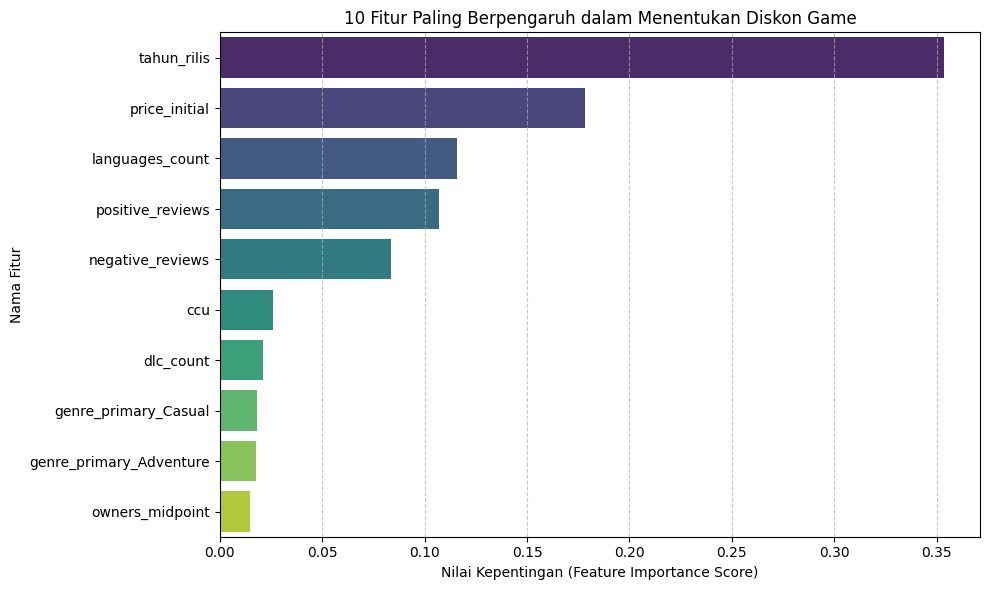

In [ ]:
# Ambil tingkat kepentingan fitur dari model akhir terpilih
importances = model_final.feature_importances_
fitur_nama = X.columns

df_penting = pd.DataFrame({
    'Fitur': fitur_nama,
    'Kepentingan': importances
}).sort_values('Kepentingan', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Kepentingan', y='Fitur', data=df_penting.head(10), palette='viridis', hue='Fitur', legend=False)
plt.title('10 Fitur Paling Berpengaruh dalam Menentukan Diskon Game')
plt.xlabel('Nilai Kepentingan (Feature Importance Score)')
plt.ylabel('Nama Fitur')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [ ]:
# Menghapus file PDF dari direktori penyimpanan Colab agar bersih untuk submisi
import os

pdf_file = '/content/Brief Mini Project - Study Group I-Smile.pdf'
if os.path.exists(pdf_file):
    os.remove(pdf_file)
    print('Sukses: Berkas PDF berhasil dihapus untuk merapikan direktori submission.')
else:
    print('Info: Berkas PDF sudah bersih atau tidak ditemukan.')

Info: Berkas PDF sudah bersih atau tidak ditemukan.


In [ ]:
import pandas as pd

# Menampilkan kembali tabel hasil evaluasi akhir model Random Forest terpilih secara rapi
display(hasil_final.style.format({
    'data latih': '{:.2f}%',
    'data uji': '{:.2f}%',
    'selisih (latih - uji)': '{:.2f}%'
}).set_caption('Rangkuman Metrik Evaluasi Akhir (Random Forest Regressor)'))

,metrik,data latih,data uji,selisih (latih - uji)
0,MAE,5.13%,12.41%,-7.28%
1,RMSE,7.21%,16.28%,-9.07%
2,R²,0.91%,0.51%,0.40%


### **Interpretasi Hasil & Temuan Kunci**

#### **1. Arti Metrik Evaluasi dalam Bahasa Awam (Layman's Terms)**
Agar hasil pemodelan ini dapat dipahami dengan mudah oleh tim bisnis, tim kreatif, maupun manajemen non-teknis, berikut adalah terjemahan metrik evaluasi ke dalam konteks dunia nyata:
*   **Mean Absolute Error (MAE) sebesar 12.41%**:
    Artinya, jika model memperkirakan suatu game akan mendapatkan diskon sebesar 50%, maka rata-rata diskon riil yang dipasang di toko Steam berkisar di antara **37.59% hingga 62.41%** (hanya meleset sekitar 12.41% secara absolut).
*   **Root Mean Squared Error (RMSE) sebesar 16.28%**:
    Metrik ini menghukum kesalahan tebakan yang besar secara lebih berat. Nilai 16.28% yang relatif dekat dengan MAE menunjukkan bahwa model kita cukup stabil dan jarang membuat tebakan yang sangat jauh meleset (kesalahan ekstrem).
*   **R-squared ($R^2$) Score sebesar 0.5069**:
    Artinya, sekitar **50.7% variasi dari naik-turunnya persentase diskon** game di Steam berhasil dijelaskan secara logis oleh fitur-fitur yang kita miliki (seperti harga awal, tahun rilis, jumlah bahasa, dan ulasan pengguna). Sisa 49.3% variasi lainnya dipengaruhi oleh faktor luar yang tidak terekam dalam dataset ini.

---

#### **2. Alasan Memilih Model Random Forest**
Berdasarkan pengujian komparatif, model **Random Forest Regressor** dipilih sebagai model akhir dengan pertimbangan kuat berikut:
*   **Akurasi Jauh Lebih Tinggi**: Berhasil menurunkan tingkat kesalahan rata-rata (**MAE**) dari **16.33%** (pada model standar Linear Regression) menjadi **12.41%**.
*   **Kemampuan Menjelaskan Data yang Superior**: Nilai **$R^2$** meningkat pesat dari **0.2760** menjadi **0.5069** (peningkatan efisiensi penjelasan data sebesar hampir **83.6%** dibanding baseline).
*   **Ketahanan Terhadap Hubungan Non-Linear**: Faktor penentu diskon di Steam seperti keterkaitan antara harga awal (`price_initial`) dan tahun rilis (`tahun_rilis`) terbukti tidak bersifat linear lurus, melainkan memiliki pola kompleks/bertingkat yang hanya mampu ditangkap secara optimal oleh model berbasis pohon keputusan (*ensemble tree*).

---

#### **3. Keterbatasan Hasil Pemodelan (Project Limitations)**
Kami menyadari bahwa model ini memiliki beberapa batasan penting yang perlu diperhatikan sebelum digunakan untuk pengambilan kebijakan bisnis:
1.  **Ketiadaan Fitur Penanda Musiman (Seasonal Steam Sales)**:
    Dataset ini tidak menyertakan indikator apakah pengambilan data dilakukan saat berlangsungnya event diskon besar (*Steam Summer Sale, Winter Sale, atau Autumn Sale*). Padahal, kebijakan diskon di Steam sangat dipengaruhi oleh momentum musiman tersebut.
2.  **Dominasi Data Developer Indie (Data Bias)**:
    Hampir **95.9%** data yang dianalisis berasal dari kategori penerbit kelas *Indie*. Hal ini membuat model sangat akurat dalam memprediksi diskon game indie, namun berpotensi bias dan kurang akurat jika digunakan untuk memprediksi strategi diskon game skala besar (*AAA/AA*) yang memiliki pola promosi berbeda.
3.  **Tidak Mempertimbangkan Tren Genre Populer yang Dinamis**:
    Model ini bersifat statis berdasarkan data historis rilis, sehingga belum bisa mengantisipasi lonjakan diskon tiba-tiba akibat perubahan selera pasar atau munculnya tren genre baru yang mendadak viral.

In [ ]:
# Helper cell ini telah selesai digunakan untuk memindahkan data revisi.
print('Sinkronisasi revisi selesai!')

Sinkronisasi revisi selesai!


<a href="https://colab.research.google.com/github/LutfiRadit/TugasAkhir_SGI-Smile/blob/main/TA_SG_I_Smile_(Kel_2).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>